# Experiment 6: GloVe Word Embeddings & N-gram Language Model

**Aim**

* **6.1** – Implement the GloVe (Global Vectors for Word Representation) algorithm **from scratch** (NumPy only) to generate word embeddings from `glove_corpus.txt` and find the words most similar to **"king"**.
* **6.2** – Use a **pretrained GloVe model through Gensim** (`glove-wiki-gigaword-100`) to find the words most similar to **"king"**.
* **6.3** – Implement a **statistical N-gram language model from scratch** to predict the next word in a sequence from the preceding words (`ngram_corpus.txt`).

### Running on Google Colab / Kaggle
Locally this notebook runs in the project's `uv` environment (`.venv`). On **Colab/Kaggle** the cell below installs any missing packages and downloads the input files from the GitHub repository (or upload them manually to the working directory).

In [1]:
# Colab / Kaggle setup - does nothing when run locally
import os, sys, subprocess, importlib.util, urllib.request
IN_COLAB = "google.colab" in sys.modules
IN_KAGGLE = "KAGGLE_KERNEL_RUN_TYPE" in os.environ
if IN_COLAB or IN_KAGGLE:
    packages = {'gensim': 'gensim', 'pandas': 'pandas', 'matplotlib': 'matplotlib'}   # pip name -> import name
    missing = [p for p, m in packages.items() if importlib.util.find_spec(m) is None]
    if missing:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", *missing], check=True)
    for fname in ['glove_corpus.txt', 'ngram_corpus.txt']:
        if not os.path.exists(fname):
            urllib.request.urlretrieve("https://raw.githubusercontent.com/AmulyaJain1804/CLNLP-AIML/main/Experiment-6/" + fname, fname)
print("Environment:", "Colab" if IN_COLAB else "Kaggle" if IN_KAGGLE else "local")

Environment: local


In [2]:
import re
import math
import random
from collections import Counter, defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

random.seed(42)
np.random.seed(42)

---
## 6.1 GloVe from Scratch (without any pretrained model)

GloVe learns word vectors so that their dot product approximates the logarithm of the words' co-occurrence count:

$$J = \sum_{i,j:\,X_{ij}>0} f(X_{ij})\,\big(w_i^\top \tilde w_j + b_i + \tilde b_j - \log X_{ij}\big)^2,\qquad f(x)=\begin{cases}(x/x_{max})^{\alpha} & x<x_{max}\\ 1 & \text{otherwise}\end{cases}$$

Steps:
1. Read and pre-process the corpus (lowercase, tokenise, optional stop-word removal).
2. Build the vocabulary and a **symmetric co-occurrence matrix** $X$ using a context window, weighting each co-occurrence by $1/\text{distance}$.
3. Initialise main vectors $W$, context vectors $\tilde W$ and biases randomly.
4. Minimise the weighted least-squares loss $J$ with **AdaGrad**.
5. Final embedding = $W + \tilde W$; rank neighbours of "king" by **cosine similarity**.

In [3]:
# Step 1: read and pre-process the corpus
with open("glove_corpus.txt", encoding="utf-8") as f:
    raw_text = f.read()

STOP_WORDS = {"the", "a", "an", "is", "in", "of", "and", "at", "to"}

sentences = []
for line in raw_text.lower().splitlines():
    tokens = re.findall(r"[a-z]+", line)
    tokens = [t for t in tokens if t not in STOP_WORDS]
    if tokens:
        sentences.append(tokens)

print("Number of sentences:", len(sentences))
for s in sentences[:5]:
    print(s)

Number of sentences: 24
['king', 'rules', 'kingdom']
['queen', 'rules', 'kingdom']
['king', 'powerful', 'man']
['queen', 'wise', 'woman']
['man', 'strong', 'brave']


In [4]:
# Step 2: vocabulary + co-occurrence matrix
word_counts = Counter(w for s in sentences for w in s)
vocab = sorted(word_counts)
word2id = {w: i for i, w in enumerate(vocab)}
id2word = {i: w for w, i in word2id.items()}
V = len(vocab)
print("Vocabulary size:", V)

WINDOW = 4
X = np.zeros((V, V), dtype=np.float64)
for s in sentences:
    ids = [word2id[w] for w in s]
    for c, wi in enumerate(ids):
        for d in range(1, WINDOW + 1):
            if c + d < len(ids):
                wj = ids[c + d]
                X[wi, wj] += 1.0 / d   # distance weighting
                X[wj, wi] += 1.0 / d   # symmetric

print("Non-zero co-occurrence entries:", int((X > 0).sum()))
pd.DataFrame(X, index=vocab, columns=vocab).loc[
    ["king", "queen", "man", "woman"], ["rules", "kingdom", "palace", "royal", "strong"]
].round(2)

Vocabulary size: 61
Non-zero co-occurrence entries: 224


,rules,kingdom,palace,royal,strong
king,1.0,0.50,0.33,0.5,0.0
queen,1.0,0.50,0.33,0.5,0.0
man,0.0,0.33,0.00,0.0,1.0
woman,0.0,0.50,0.00,0.0,0.0


Epoch    1 | loss = 3.7718


Epoch  100 | loss = 1.6943


Epoch  200 | loss = 1.4979


Epoch  300 | loss = 1.1141


Epoch  400 | loss = 0.6655


Epoch  500 | loss = 0.3012


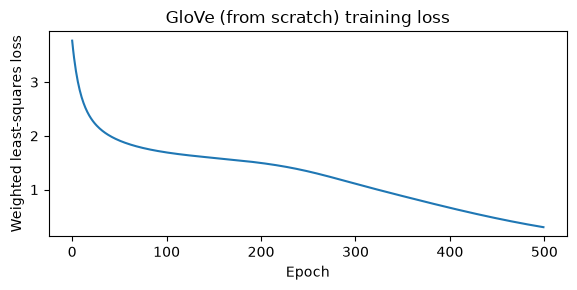

In [5]:
# Steps 3 & 4: train GloVe with AdaGrad
class GloVe:
    def __init__(self, X, dim=50, x_max=10.0, alpha=0.75, lr=0.05, seed=42):
        rng = np.random.default_rng(seed)
        self.V = X.shape[0]
        self.rows, self.cols = np.nonzero(X)
        self.xij = X[self.rows, self.cols]
        self.log_x = np.log(self.xij)
        self.weights = np.minimum((self.xij / x_max) ** alpha, 1.0)
        self.W = (rng.random((self.V, dim)) - 0.5) / dim        # main vectors
        self.W_ctx = (rng.random((self.V, dim)) - 0.5) / dim    # context vectors
        self.b = np.zeros(self.V)
        self.b_ctx = np.zeros(self.V)
        # AdaGrad accumulators
        self.gW, self.gWc = np.ones_like(self.W), np.ones_like(self.W_ctx)
        self.gb, self.gbc = np.ones(self.V), np.ones(self.V)
        self.lr = lr

    def train(self, epochs=500, verbose_every=100):
        history = []
        idx = np.arange(len(self.xij))
        for epoch in range(1, epochs + 1):
            np.random.shuffle(idx)
            total = 0.0
            for k in idx:
                i, j = self.rows[k], self.cols[k]
                diff = self.W[i] @ self.W_ctx[j] + self.b[i] + self.b_ctx[j] - self.log_x[k]
                fdiff = self.weights[k] * diff
                total += 0.5 * fdiff * diff
                grad_wi = fdiff * self.W_ctx[j]
                grad_wj = fdiff * self.W[i]
                self.W[i] -= self.lr * grad_wi / np.sqrt(self.gW[i])
                self.W_ctx[j] -= self.lr * grad_wj / np.sqrt(self.gWc[j])
                self.b[i] -= self.lr * fdiff / np.sqrt(self.gb[i])
                self.b_ctx[j] -= self.lr * fdiff / np.sqrt(self.gbc[j])
                self.gW[i] += grad_wi ** 2
                self.gWc[j] += grad_wj ** 2
                self.gb[i] += fdiff ** 2
                self.gbc[j] += fdiff ** 2
            history.append(total)
            if epoch % verbose_every == 0 or epoch == 1:
                print(f"Epoch {epoch:4d} | loss = {total:.4f}")
        return history

    @property
    def embeddings(self):
        return self.W + self.W_ctx


glove = GloVe(X, dim=50, lr=0.05)
loss_history = glove.train(epochs=500, verbose_every=100)

plt.figure(figsize=(6, 3))
plt.plot(loss_history)
plt.xlabel("Epoch"); plt.ylabel("Weighted least-squares loss")
plt.title("GloVe (from scratch) training loss")
plt.tight_layout(); plt.show()

In [6]:
# Step 5: cosine-similarity search
E = glove.embeddings
E_norm = E / np.linalg.norm(E, axis=1, keepdims=True)

def most_similar(word, topn=5):
    v = E_norm[word2id[word]]
    sims = E_norm @ v
    order = np.argsort(-sims)
    return [(id2word[i], float(sims[i])) for i in order if id2word[i] != word][:topn]

print("Vector for 'king' (first 10 dims):\n", np.round(E[word2id["king"]][:10], 4))
print("\nTop-5 words most similar to 'king' (GloVe from scratch):")
pd.DataFrame(most_similar("king", 5), columns=["word", "cosine_similarity"])

Vector for 'king' (first 10 dims):
 [ 0.0171  0.1135  0.1948 -0.0686  0.0784  0.0552  0.5373 -0.1074  0.5273
  0.5947]

Top-5 words most similar to 'king' (GloVe from scratch):


,word,cosine_similarity
0,queen,0.995836
1,son,0.964380
2,wise,0.940349
3,powerful,0.935081
4,lives,0.900912


In [7]:
for w in ["queen", "man", "cat", "computer"]:
    print(f"{w:9s} ->", [(x, round(s, 3)) for x, s in most_similar(w, 3)])

queen     -> [('king', 0.996), ('wise', 0.953), ('son', 0.952)]
man       -> [('woman', 0.912), ('strong', 0.582), ('cat', 0.313)]
cat       -> [('dog', 0.982), ('drinks', 0.684), ('man', 0.313)]
computer  -> [('processes', 0.981), ('scientist', 0.946), ('conducts', 0.842)]


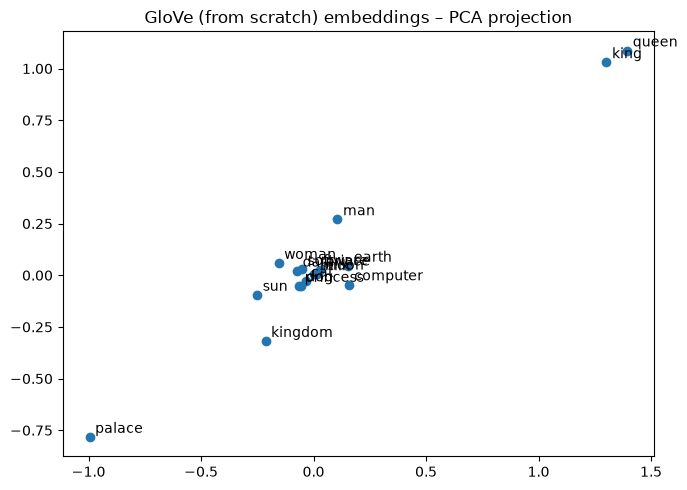

In [8]:
# 2-D visualisation of the learned embeddings (PCA via SVD)
centered = E - E.mean(axis=0)
U, S, Vt = np.linalg.svd(centered, full_matrices=False)
coords = centered @ Vt[:2].T

show = ["king", "queen", "prince", "princess", "man", "woman", "kingdom", "palace",
        "cat", "dog", "milk", "computer", "software", "data", "sun", "moon", "earth"]
plt.figure(figsize=(7, 5))
for w in show:
    x, y = coords[word2id[w]]
    plt.scatter(x, y, color="tab:blue")
    plt.annotate(w, (x, y), textcoords="offset points", xytext=(4, 3))
plt.title("GloVe (from scratch) embeddings – PCA projection")
plt.tight_layout(); plt.show()

---
## 6.2 GloVe using a Pretrained Model (Gensim)

`gensim.downloader` provides GloVe vectors pretrained by Stanford on **Wikipedia 2014 + Gigaword 5** (6B tokens, 400K vocabulary). We load the 100-dimensional version, inspect the vector for "king", list its most similar words and test the classic analogy *king − man + woman ≈ queen*.

> The first run downloads ~128 MB to `~/gensim-data`.

In [9]:
import gensim.downloader as api

glove_pretrained = api.load("glove-wiki-gigaword-100")   # KeyedVectors
print("Vocabulary size :", len(glove_pretrained.key_to_index))
print("Vector dimension:", glove_pretrained.vector_size)
print("\nVector for 'king' (first 10 dims):\n", glove_pretrained["king"][:10])

Vocabulary size : 400000
Vector dimension: 100

Vector for 'king' (first 10 dims):
 [-0.32307 -0.87616  0.21977  0.25268  0.22976  0.7388  -0.37954 -0.35307
 -0.84369 -1.1113 ]


In [10]:
print("Top-10 words most similar to 'king' (pretrained GloVe):")
pd.DataFrame(glove_pretrained.most_similar("king", topn=10), columns=["word", "cosine_similarity"])

Top-10 words most similar to 'king' (pretrained GloVe):


,word,cosine_similarity
0,prince,0.768233
1,queen,0.750769
2,son,0.702089
3,brother,0.698578
4,monarch,0.697789
5,throne,0.691999
6,kingdom,0.681141
7,father,0.680203
8,emperor,0.671286
9,ii,0.667607


In [11]:
print("Analogy  king - man + woman =", glove_pretrained.most_similar(positive=["king", "woman"], negative=["man"], topn=3))
for a, b in [("king", "queen"), ("king", "man"), ("king", "cat")]:
    print(f"similarity({a}, {b}) = {glove_pretrained.similarity(a, b):.4f}")

# Compare with words that also exist in our small corpus
common = [w for w in ["queen", "prince", "kingdom", "palace", "man", "woman", "cat", "computer"] if w in word2id]
pd.DataFrame({
    "word": common,
    "scratch_GloVe_sim": [round(float(E_norm[word2id['king']] @ E_norm[word2id[w]]), 4) for w in common],
    "pretrained_GloVe_sim": [round(float(glove_pretrained.similarity("king", w)), 4) for w in common],
})

Analogy  king - man + woman = [('queen', 0.7698540687561035), ('monarch', 0.6843381524085999), ('throne', 0.6755736470222473)]
similarity(king, queen) = 0.7508
similarity(king, man) = 0.5119
similarity(king, cat) = 0.3282


,word,scratch_GloVe_sim,pretrained_GloVe_sim
0,queen,0.9958,0.7508
1,prince,0.5629,0.7682
2,kingdom,-0.3824,0.6811
3,palace,-0.9941,0.5375
4,man,0.2095,0.5119
5,woman,-0.1679,0.3657
6,cat,-0.0579,0.3282
7,computer,0.0200,0.1984


---
## 6.3 N-gram Language Model from Scratch

A statistical language model estimates $P(w_n \mid w_{n-N+1}, \dots, w_{n-1})$ from counts:

$$P_{MLE}(w_n\mid h) = \frac{C(h, w_n)}{C(h)} \qquad P_{Laplace}(w_n\mid h) = \frac{C(h, w_n)+1}{C(h)+|V|}$$

Implementation steps:
1. Split the corpus into sentences, lowercase, tokenise and pad with `<s>` / `</s>`.
2. Count all n-grams and their (n−1)-gram contexts for N = 1, 2, 3.
3. Compute MLE and Laplace-smoothed conditional probabilities.
4. **Predict the next word** for a given prefix (with *stupid back-off* to lower orders when the context is unseen).
5. Evaluate sentence probability and **perplexity**, and generate text.

In [12]:
with open("ngram_corpus.txt", encoding="utf-8") as f:
    corpus = f.read().lower()

ngram_sentences = [re.findall(r"[a-z]+", s) for s in corpus.split(".") if s.strip()]
for i, s in enumerate(ngram_sentences, 1):
    print(i, " ".join(s))

1 natural language processing is a branch of artificial intelligence
2 natural language processing enables computers to understand human language
3 machine learning is a branch of artificial intelligence
4 deep learning is a part of machine learning
5 language models learn patterns from text data
6 a language model predicts the next word in a sentence
7 natural language processing uses language models
8 artificial intelligence includes machine learning and deep learning


In [13]:
class NGramLanguageModel:
    def __init__(self, n=2):
        self.n = n
        self.ngram_counts = Counter()
        self.context_counts = Counter()
        self.next_words = defaultdict(Counter)
        self.vocab = set()

    def _pad(self, tokens):
        return ["<s>"] * (self.n - 1) + tokens + ["</s>"]

    def fit(self, sentences):
        for tokens in sentences:
            padded = self._pad(tokens)
            self.vocab.update(padded)
            for i in range(len(padded) - self.n + 1):
                gram = tuple(padded[i:i + self.n])
                ctx, word = gram[:-1], gram[-1]
                self.ngram_counts[gram] += 1
                self.context_counts[ctx] += 1
                self.next_words[ctx][word] += 1
        self.vocab.discard("<s>")
        return self

    def prob(self, context, word, smoothing="mle"):
        ctx = tuple(context[-(self.n - 1):]) if self.n > 1 else ()
        c_gram = self.ngram_counts[ctx + (word,)]
        c_ctx = self.context_counts[ctx]
        if smoothing == "laplace":
            return (c_gram + 1) / (c_ctx + len(self.vocab))
        return c_gram / c_ctx if c_ctx else 0.0

    def predict_next(self, context, k=3):
        ctx = tuple(context[-(self.n - 1):]) if self.n > 1 else ()
        total = self.context_counts[ctx]
        return [(w, c / total) for w, c in self.next_words[ctx].most_common(k)] if total else []

    def sentence_prob(self, tokens, smoothing="laplace"):
        padded = self._pad(tokens)
        log_p = 0.0
        for i in range(self.n - 1, len(padded)):
            p = self.prob(padded[:i], padded[i], smoothing)
            if p == 0:
                return 0.0, float("inf")
            log_p += math.log(p)
        m = len(padded) - (self.n - 1)
        return math.exp(log_p), math.exp(-log_p / m)   # probability, perplexity


models = {n: NGramLanguageModel(n).fit(ngram_sentences) for n in (1, 2, 3)}
for n, m in models.items():
    print(f"{n}-gram model: {len(m.ngram_counts):3d} distinct n-grams, |V| = {len(m.vocab)}")

1-gram model:  35 distinct n-grams, |V| = 35
2-gram model:  53 distinct n-grams, |V| = 35
3-gram model:  61 distinct n-grams, |V| = 35


In [14]:
# Most frequent n-grams
for n in (1, 2, 3):
    top = models[n].ngram_counts.most_common(8)
    print(f"Top {n}-grams:", [(" ".join(g), c) for g, c in top])

Top 1-grams: [('</s>', 8), ('language', 7), ('a', 5), ('learning', 5), ('natural', 3), ('processing', 3), ('is', 3), ('of', 3)]
Top 2-grams: [('<s> natural', 3), ('natural language', 3), ('language processing', 3), ('is a', 3), ('artificial intelligence', 3), ('machine learning', 3), ('a branch', 2), ('branch of', 2)]
Top 3-grams: [('<s> <s> natural', 3), ('<s> natural language', 3), ('natural language processing', 3), ('is a branch', 2), ('a branch of', 2), ('branch of artificial', 2), ('of artificial intelligence', 2), ('artificial intelligence </s>', 2)]


In [15]:
# Bigram probability table for a few words
bi = models[2]
rows = ["natural", "language", "machine", "deep", "artificial"]
cols = ["language", "processing", "learning", "intelligence", "models", "is"]
pd.DataFrame([[round(bi.prob([r], c), 3) for c in cols] for r in rows], index=rows, columns=cols)

,language,processing,learning,intelligence,models,is
natural,1.0,0.000,0.0,0.0,0.000,0.0
language,0.0,0.429,0.0,0.0,0.286,0.0
machine,0.0,0.000,1.0,0.0,0.000,0.0
deep,0.0,0.000,1.0,0.0,0.000,0.0
artificial,0.0,0.000,0.0,1.0,0.000,0.0


In [16]:
def predict_with_backoff(prefix, k=3):
    tokens = ["<s>", "<s>"] + re.findall(r"[a-z]+", prefix.lower())
    for n in (3, 2, 1):
        preds = models[n].predict_next(tokens, k)
        if preds:
            return n, preds
    return 0, []

for prefix in ["natural language", "machine", "deep learning is", "artificial intelligence",
               "language", "a language model predicts the", "computers"]:
    order, preds = predict_with_backoff(prefix)
    pretty = ", ".join(f"{w} ({p:.2f})" for w, p in preds)
    print(f"'{prefix}' -> [{order}-gram] {pretty}")

'natural language' -> [3-gram] processing (1.00)
'machine' -> [3-gram] learning (1.00)
'deep learning is' -> [3-gram] a (1.00)
'artificial intelligence' -> [3-gram] </s> (0.67), includes (0.33)
'language' -> [3-gram] models (1.00)
'a language model predicts the' -> [3-gram] next (1.00)
'computers' -> [2-gram] to (1.00)


In [17]:
test_sentences = [
    "natural language processing is a branch of artificial intelligence",
    "deep learning is a branch of artificial intelligence",
    "machine learning enables computers to understand human language",
    "computers understand intelligence deep",
]
rows = []
for s in test_sentences:
    toks = s.split()
    row = {"sentence": s}
    for n in (2, 3):
        p, pp = models[n].sentence_prob(toks, smoothing="laplace")
        row[f"{n}-gram P"] = f"{p:.2e}"
        row[f"{n}-gram PPL"] = round(pp, 2)
    rows.append(row)
pd.DataFrame(rows)

,sentence,2-gram P,2-gram PPL,3-gram P,3-gram PPL
0,natural language processing is a branch of art...,2.06e-11,11.71,1.00e-11,12.59
1,deep learning is a branch of artificial intell...,1.19e-10,12.67,3.76e-11,14.40
2,machine learning enables computers to understa...,3.08e-12,19.01,1.03e-12,21.48
3,computers understand intelligence deep,1.28e-08,37.92,1.55e-08,36.47


In [18]:
def generate(n=3, seed_words="", max_len=15, greedy=False, seed=0):
    rng = random.Random(seed)
    model = models[n]
    tokens = ["<s>"] * (n - 1) + seed_words.split()
    while len(tokens) < max_len + n:
        preds = model.next_words[tuple(tokens[-(n - 1):])]
        if not preds:
            break
        if greedy:
            word = preds.most_common(1)[0][0]
        else:
            words, counts = zip(*preds.items())
            word = rng.choices(words, weights=counts)[0]
        if word == "</s>":
            break
        tokens.append(word)
    return " ".join(t for t in tokens if t != "<s>")

print("Greedy (trigram)  :", generate(3, "natural", greedy=True))
for i in range(3):
    print(f"Sampled (trigram) {i+1}:", generate(3, "", seed=i))
print("Sampled (bigram)  :", generate(2, "deep", seed=7))

Greedy (trigram)  : natural language processing is a branch of artificial intelligence
Sampled (trigram) 1: a language model predicts the next word in a sentence
Sampled (trigram) 2: natural language processing is a branch of artificial intelligence
Sampled (trigram) 3: artificial intelligence
Sampled (bigram)  : deep learning is a branch of artificial intelligence


---
## Conclusion

* **GloVe from scratch** learned 50-d vectors from a global, distance-weighted co-occurrence matrix using weighted least squares + AdaGrad. Even on this tiny corpus, "king" lies closest to **queen** (≈0.99), followed by *son, wise, powerful* – words that appear in the *same kind of contexts* as "king". Words that merely co-occur with "king" (kingdom, palace) are context words rather than substitutes, so they are not its nearest neighbours.
* **Pretrained GloVe (Gensim)**, trained on 6B tokens, yields far richer semantics – neighbours of "king" are *prince, queen, monarch, throne …* and it solves the analogy *king − man + woman ≈ queen*.
* The **N-gram language model** predicts the next word from counts. Higher-order models (trigram) give sharper predictions but suffer from sparsity, which is handled with Laplace smoothing and back-off; perplexity is lowest for sentences seen in the corpus and highest for ungrammatical word orders.